# EDA de Datos Crudos — Criminalidad y Seguridad Ciudadana en el Perú (MININTER)

**Objetivo:** Realizar un Análisis Exploratorio de Datos (EDA) exhaustivo sobre los **4 datasets crudos** en `Dataset-Crudo/` utilizando **PySpark SQL** y **Matplotlib** para diagnosticar problemas de calidad (codificación, nulos, ubigeos, formatos de fecha/mes, años parciales, mezclas de unidades y códigos desalineados) que fundamentan las reglas de limpieza de los ETL hacia los DataMarts.

**Datasets analizados:**
1. **Denuncias Policiales (2018–2026):** 9 archivos CSV (`Dataset-Crudo/Denuncias-Policiales_2018-2026/`)
2. **Personas Desaparecidas (2019–2025):** 1 archivo CSV (`Dataset-Crudo/Personas-Desaparecidas_2019-2025/`)
3. **Producción Policial (2023–2026):** 4 archivos CSV (`Dataset-Crudo/Produccion-Policial_2023-2026/`)
4. **Indicadores de Victimización y Confianza PNP (2013–2024):** 1 archivo CSV (`Dataset-Crudo/Indicadores-de-Victimizacion-y-confianza-PNP_2013-2024/`)

> Todas las métricas resumen, tablas CSV y gráficas Matplotlib se exportan automáticamente a `EDA/EDA-Datos-Crudos/outputs/` para su presentación instantánea en **Streamlit**.

In [1]:
import os
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pyspark.sql import SparkSession

# Configuración visual de Matplotlib
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

# Rutas del proyecto (funciona tanto si se ejecuta desde raíz como desde EDA/EDA-Datos-Crudos)
CWD = Path.cwd()
if (CWD / "Dataset-Crudo").exists():
    PROJECT_ROOT = CWD
elif (CWD.parent.parent / "Dataset-Crudo").exists():
    PROJECT_ROOT = CWD.parent.parent
else:
    PROJECT_ROOT = Path(r"c:\Users\rodry20x\Documents\Clases-UPN\Ciclo_2026-2\BigDATA\EF_Final")

RAW_DIR = PROJECT_ROOT / "Dataset-Crudo"
OUT_DIR = PROJECT_ROOT / "EDA" / "EDA-Datos-Crudos" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("OUT_DIR     :", OUT_DIR)

# Inicializar SparkSession local
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("EDA_Datos_Crudos_EF_Final")
    .config("spark.ui.enabled", "false")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("PySpark version:", spark.version)

PROJECT_ROOT: C:\Users\rodry20x\Documents\Clases-UPN\Ciclo_2026-2\BigDATA\EF_Final
OUT_DIR     : C:\Users\rodry20x\Documents\Clases-UPN\Ciclo_2026-2\BigDATA\EF_Final\EDA\EDA-Datos-Crudos\outputs


PySpark version: 4.2.0


## 1. Diagnóstico de Archivos y Codificación de Origen

Antes de cargar en PySpark, verificamos la codificación real de cada CSV crudo probando `utf-8-sig` vs `cp1252` (Windows-1252). Esto evidencia por qué **Personas Desaparecidas** y **Victimización y Confianza PNP** corrompen tildes y la letra `Ñ` si se leen directamente como UTF-8.

In [2]:
def detectar_codificacion(path: Path) -> dict:
    raw_bytes = path.read_bytes()
    has_bom = raw_bytes.startswith(b"\xef\xbb\xbf")
    try:
        raw_bytes.decode("utf-8-sig")
        enc = "utf-8-sig" if has_bom else "utf-8"
        utf8_valido = True
    except UnicodeDecodeError:
        enc = "cp1252"
        utf8_valido = False
    return {
        "archivo": path.name,
        "carpeta": path.parent.name,
        "bytes": len(raw_bytes),
        "kb": round(len(raw_bytes) / 1024, 1),
        "codificacion_detectada": enc,
        "utf8_valido": utf8_valido,
    }

raw_files = sorted([
    p for p in RAW_DIR.rglob("*.csv")
    if "0-Diccionario-de-datos" not in str(p)
])
df_archivos = pd.DataFrame([detectar_codificacion(p) for p in raw_files])
df_archivos.to_csv(OUT_DIR / "archivos_codificacion_crudos.csv", index=False, encoding="utf-8-sig")
display(df_archivos)

,archivo,carpeta,bytes,kb,codificacion_detectada,utf8_valido
0,Denuncias_Policiales_2018.csv,Denuncias-Policiales_2018-2026,1948361,1902.7,utf-8,True
1,Denuncias_Policiales_2019.csv,Denuncias-Policiales_2018-2026,2259214,2206.3,utf-8,True
2,Denuncias_Policiales_2020.csv,Denuncias-Policiales_2018-2026,2270232,2217.0,utf-8,True
3,Denuncias_Policiales_2021.csv,Denuncias-Policiales_2018-2026,2590508,2529.8,utf-8,True
4,Denuncias_Policiales_2022.csv,Denuncias-Policiales_2018-2026,2744349,2680.0,utf-8,True
5,Denuncias_Policiales_2023.csv,Denuncias-Policiales_2018-2026,2837944,2771.4,utf-8,True
6,Denuncias_Policiales_2024.csv,Denuncias-Policiales_2018-2026,2837929,2771.4,utf-8,True
7,Denuncias_Policiales_2025.csv,Denuncias-Policiales_2018-2026,2731098,2667.1,utf-8,True
8,Denuncias_Policiales_2026.csv,Denuncias-Policiales_2018-2026,2218639,2166.6,utf-8,True
9,Victimización-Percepción-de-Inseguridad-y-Conf...,Indicadores-de-Victimizacion-y-confianza-PNP_2...,159784,156.0,cp1252,False


## 2. Carga en PySpark y Registro de Vistas Temporales SQL

Cargamos los 4 datasets crudos en DataFrames de PySpark especificando la codificación detectada (`UTF-8` o `windows-1252`), normalizamos solo el BOM invisible (`\ufeff`) en nombres de columna si existiera y registramos las 4 vistas temporales para realizar todo el EDA con **PySpark SQL**:
- `raw_denuncias`
- `raw_desaparecidos`
- `raw_produccion`
- `raw_victimizacion`

In [3]:
def limpiar_nombres_bom(df):
    for c in df.columns:
        clean = c.lstrip("\ufeff").strip()
        if clean != c:
            df = df.withColumnRenamed(c, clean)
    return df

# 1. Denuncias Policiales (9 CSVs, UTF-8)
denuncias_paths = [str(p) for p in sorted((RAW_DIR / "Denuncias-Policiales_2018-2026").glob("*.csv"))]
df_raw_denuncias = limpiar_nombres_bom(
    spark.read.option("header", True).option("encoding", "UTF-8").csv(denuncias_paths)
)
df_raw_denuncias.createOrReplaceTempView("raw_denuncias")

# 2. Personas Desaparecidas (1 CSV, CP1252 -> ISO-8859-1 compatible en PySpark 4)
desap_path = str(RAW_DIR / "Personas-Desaparecidas_2019-2025" / "Personas_Desaparecidas_2019_2025.csv")
df_raw_desaparecidos = limpiar_nombres_bom(
    spark.read.option("header", True).option("encoding", "ISO-8859-1").csv(desap_path)
)
df_raw_desaparecidos.createOrReplaceTempView("raw_desaparecidos")

# 3. Producción Policial (4 CSVs, UTF-8 con BOM)
prod_paths = [str(p) for p in sorted((RAW_DIR / "Produccion-Policial_2023-2026").glob("*.csv"))]
df_raw_produccion = limpiar_nombres_bom(
    spark.read.option("header", True).option("encoding", "UTF-8").csv(prod_paths)
)
df_raw_produccion.createOrReplaceTempView("raw_produccion")

# 4. Victimización y Confianza PNP (1 CSV, CP1252 -> ISO-8859-1 compatible en PySpark 4)
vict_files = list((RAW_DIR / "Indicadores-de-Victimizacion-y-confianza-PNP_2013-2024").glob("*.csv"))
vict_path = str(vict_files[0])
df_raw_victimizacion = limpiar_nombres_bom(
    spark.read.option("header", True).option("encoding", "ISO-8859-1").csv(vict_path)
)
df_raw_victimizacion.createOrReplaceTempView("raw_victimizacion")

# Resumen general vía PySpark SQL
resumen_general_df = spark.sql("""
    SELECT '1. Denuncias Policiales' AS dataset,
           COUNT(*) AS filas_crudas,
           MIN(CAST(ANIO_REGISTRO AS INT)) AS anio_min,
           MAX(CAST(ANIO_REGISTRO AS INT)) AS anio_max,
           'UTF-8' AS codificacion,
           'Mensual / Distrito / Modalidad' AS grano_crudo
    FROM raw_denuncias
    UNION ALL
    SELECT '2. Personas Desaparecidas',
           COUNT(*),
           MIN(CAST(`AÑO` AS INT)),
           MAX(CAST(`AÑO` AS INT)),
           'CP1252 (requiere UTF-8)',
           'Mensual / Distrito / Sexo / Edad / Nac.'
    FROM raw_desaparecidos
    UNION ALL
    SELECT '3. Producción Policial',
           COUNT(*),
           MIN(CAST(`AÑO` AS INT)),
           MAX(CAST(`AÑO` AS INT)),
           'UTF-8 BOM',
           'Mensual (texto) / Dependencia / Variable'
    FROM raw_produccion
    UNION ALL
    SELECT '4. Victimización y Confianza PNP',
           COUNT(*),
           MIN(CAST(`VALOR PERIODO` AS INT)),
           MAX(CAST(`VALOR PERIODO` AS INT)),
           'CP1252 (requiere UTF-8)',
           'Anual / Ámbito / Indicador'
    FROM raw_victimizacion
""").toPandas()

resumen_general_df.to_csv(OUT_DIR / "resumen_general_crudos.csv", index=False, encoding="utf-8-sig")
display(resumen_general_df)

,dataset,filas_crudas,anio_min,anio_max,codificacion,grano_crudo
0,1. Denuncias Policiales,378187,2018,2026,UTF-8,Mensual / Distrito / Modalidad
1,2. Personas Desaparecidas,77331,2019,2025,CP1252 (requiere UTF-8),Mensual / Distrito / Sexo / Edad / Nac.
2,3. Producción Policial,39096,2023,2026,UTF-8 BOM,Mensual (texto) / Dependencia / Variable
3,4. Victimización y Confianza PNP,1592,2013,2024,CP1252 (requiere UTF-8),Anual / Ámbito / Indicador


## 3. EDA Crudo — Dataset 1: Denuncias Policiales (2018–2026)

Consultas **PySpark SQL** para auditar:
- Cobertura de meses y volumen por año (identificando **2026 parcial: solo enero–octubre**).
- Pérdida de ceros a la izquierda en `UBIGEO_HECHO` (códigos de 5 dígitos en departamentos `01`–`09`).
- Conflictos de nombres para un mismo ubigeo (ej. `160801`: `MAYNAS` vs `PUTUMAYO`).
- Nulos, cantidades negativas y duplicados por grano.

In [4]:
d1_anual = spark.sql("""
    SELECT CAST(ANIO_REGISTRO AS INT) AS anio,
           COUNT(*) AS filas,
           COUNT(DISTINCT CAST(MES_REGISTRO AS INT)) AS meses_distintos,
           SUM(CAST(cantidad AS BIGINT)) AS total_denuncias,
           SUM(CASE WHEN LENGTH(TRIM(UBIGEO_HECHO)) < 6 THEN 1 ELSE 0 END) AS ubigeos_sin_cero_izq
    FROM raw_denuncias
    GROUP BY CAST(ANIO_REGISTRO AS INT)
    ORDER BY anio
""").toPandas()

d1_ubigeo_len = spark.sql("""
    SELECT LENGTH(TRIM(UBIGEO_HECHO)) AS longitud_ubigeo,
           COUNT(*) AS filas
    FROM raw_denuncias
    GROUP BY LENGTH(TRIM(UBIGEO_HECHO))
    ORDER BY longitud_ubigeo
""").toPandas()

d1_conflicto_160801 = spark.sql("""
    SELECT LPAD(TRIM(UBIGEO_HECHO), 6, '0') AS ubigeo_norm,
           TRIM(DPTO_HECHO_NEW) AS departamento,
           TRIM(PROV_HECHO) AS provincia,
           TRIM(DIST_HECHO) AS distrito,
           COUNT(*) AS filas
    FROM raw_denuncias
    WHERE LPAD(TRIM(UBIGEO_HECHO), 6, '0') = '160801'
    GROUP BY LPAD(TRIM(UBIGEO_HECHO), 6, '0'), TRIM(DPTO_HECHO_NEW), TRIM(PROV_HECHO), TRIM(DIST_HECHO)
    ORDER BY filas DESC
""").toPandas()

d1_calidad = spark.sql("""
    SELECT
        COUNT(*) AS total_filas,
        SUM(CAST(cantidad AS BIGINT)) AS total_denuncias,
        SUM(CASE WHEN ANIO_REGISTRO IS NULL OR MES_REGISTRO IS NULL OR UBIGEO_HECHO IS NULL OR P_MODALIDADES IS NULL OR cantidad IS NULL THEN 1 ELSE 0 END) AS filas_con_nulos,
        SUM(CASE WHEN CAST(cantidad AS INT) < 0 THEN 1 ELSE 0 END) AS cantidades_negativas,
        SUM(CASE WHEN LENGTH(TRIM(UBIGEO_HECHO)) < 6 THEN 1 ELSE 0 END) AS ubigeos_5_digitos,
        COUNT(*) - COUNT(DISTINCT CONCAT_WS('|', ANIO_REGISTRO, MES_REGISTRO, LPAD(TRIM(UBIGEO_HECHO), 6, '0'), TRIM(P_MODALIDADES))) AS duplicados_grano
    FROM raw_denuncias
""").toPandas()

d1_modalidad = spark.sql("""
    SELECT TRIM(P_MODALIDADES) AS modalidad,
           COUNT(*) AS filas,
           SUM(CAST(cantidad AS BIGINT)) AS total_denuncias
    FROM raw_denuncias
    GROUP BY TRIM(P_MODALIDADES)
    ORDER BY total_denuncias DESC
""").toPandas()

d1_anual.to_csv(OUT_DIR / "d1_crudo_anual.csv", index=False, encoding="utf-8-sig")
d1_conflicto_160801.to_csv(OUT_DIR / "d1_crudo_conflicto_ubigeo.csv", index=False, encoding="utf-8-sig")
d1_modalidad.to_csv(OUT_DIR / "d1_crudo_modalidad.csv", index=False, encoding="utf-8-sig")

print("--- Calidad D1 (Crudo) ---")
display(d1_calidad)
print("--- Cobertura Anual D1 ---")
display(d1_anual)
print("--- Conflicto Ubigeo 160801 ---")
display(d1_conflicto_160801)

--- Calidad D1 (Crudo) ---


,total_filas,total_denuncias,filas_con_nulos,cantidades_negativas,ubigeos_5_digitos,duplicados_grano
0,378187,7614774,0,0,146690,0


--- Cobertura Anual D1 ---


,anio,filas,meses_distintos,total_denuncias,ubigeos_sin_cero_izq
0,2018,32879,12,771473,12437
1,2019,37877,12,852706,14245
2,2020,37651,12,646083,14803
3,2021,43165,12,754041,17109
4,2022,46199,12,876489,18076
5,2023,48124,12,1042205,18811
6,2024,48235,12,1017082,18732
7,2025,46374,12,906527,17846
8,2026,37683,10,748168,14631


--- Conflicto Ubigeo 160801 ---


,ubigeo_norm,departamento,provincia,distrito,filas
0,160801,LORETO,MAYNAS,PUTUMAYO,55
1,160801,LORETO,PUTUMAYO,PUTUMAYO,52


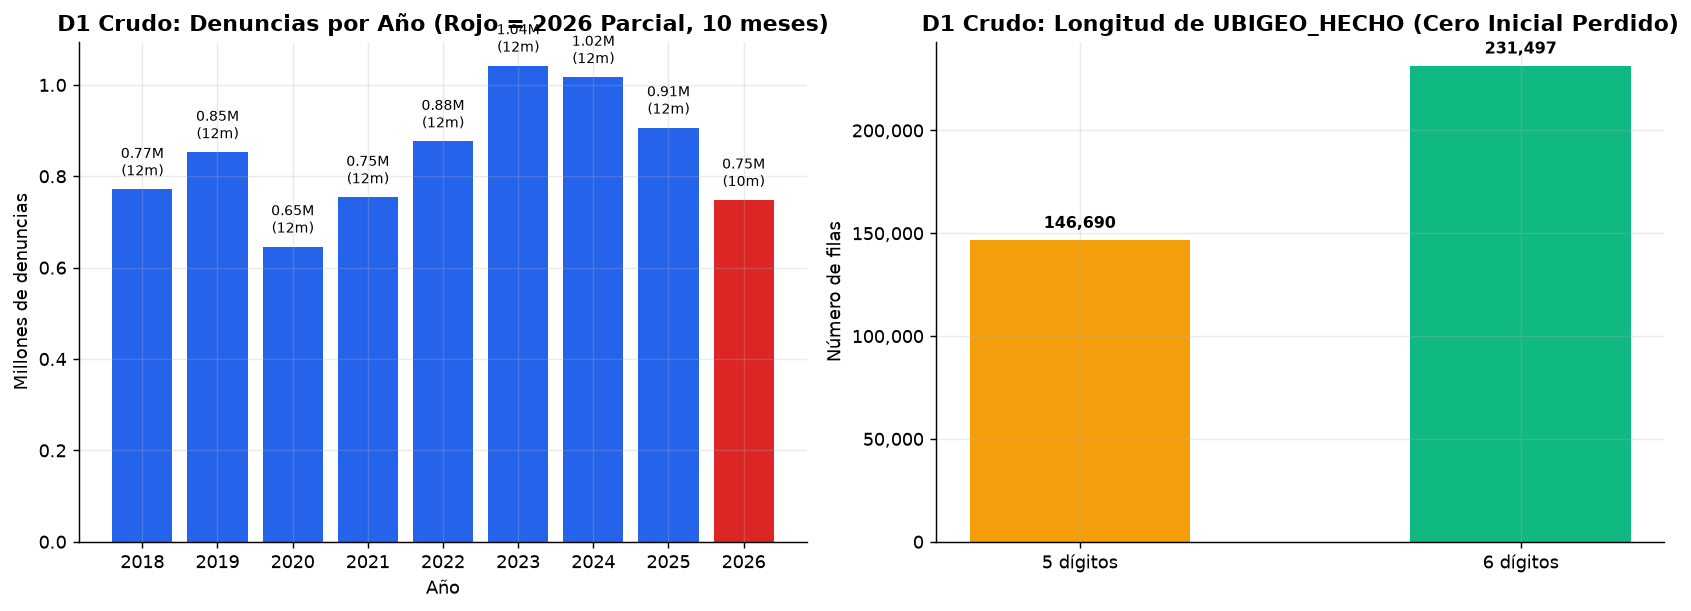

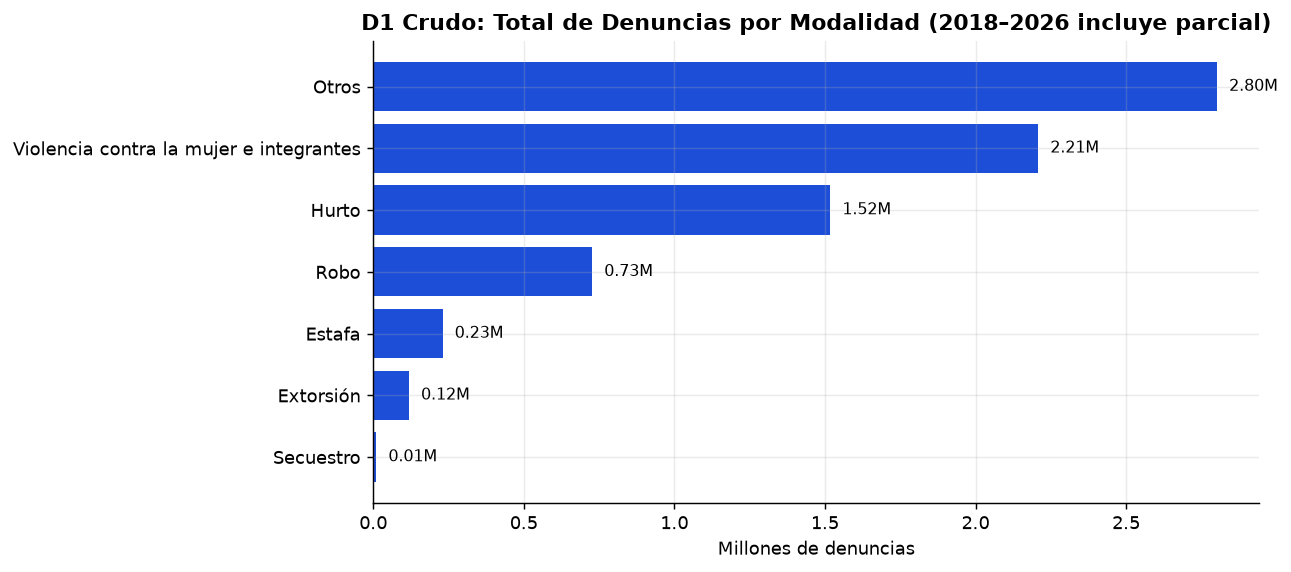

In [5]:
# Gráfica 1: Cobertura anual y detección de 2026 parcial (D1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

colors_yr = ["#2563EB" if m == 12 else "#DC2626" for m in d1_anual["meses_distintos"]]
bars = axes[0].bar(d1_anual["anio"].astype(str), d1_anual["total_denuncias"] / 1e6, color=colors_yr)
axes[0].set_title("D1 Crudo: Denuncias por Año (Rojo = 2026 Parcial, 10 meses)", fontweight="bold")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Millones de denuncias")
for b, m in zip(bars, d1_anual["meses_distintos"]):
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 0.02, f"{h:.2f}M\n({m}m)", ha="center", va="bottom", fontsize=8)

# Subgráfico 2: Ubigeos con cero inicial perdido vs completos
labels_u = [f"{int(x)} dígitos" for x in d1_ubigeo_len["longitud_ubigeo"]]
colors_u = ["#F59E0B" if x < 6 else "#10B981" for x in d1_ubigeo_len["longitud_ubigeo"]]
bars2 = axes[1].bar(labels_u, d1_ubigeo_len["filas"], color=colors_u, width=0.5)
axes[1].set_title("D1 Crudo: Longitud de UBIGEO_HECHO (Cero Inicial Perdido)", fontweight="bold")
axes[1].set_ylabel("Número de filas")
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
for b in bars2:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, h + 4000, f"{int(h):,}", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(OUT_DIR / "01_crudo_denuncias_cobertura_ubigeo.png", dpi=150, bbox_inches="tight")
plt.show()

# Gráfica 2: Modalidades delictivas en el crudo
fig, ax = plt.subplots(figsize=(10, 4.5))
df_m = d1_modalidad.sort_values("total_denuncias", ascending=True)
bars = ax.barh(df_m["modalidad"], df_m["total_denuncias"] / 1e6, color="#1D4ED8")
ax.set_title("D1 Crudo: Total de Denuncias por Modalidad (2018–2026 incluye parcial)", fontweight="bold")
ax.set_xlabel("Millones de denuncias")
for b in bars:
    w = b.get_width()
    ax.text(w + 0.04, b.get_y() + b.get_height()/2, f"{w:.2f}M", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "02_crudo_denuncias_modalidades.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. EDA Crudo — Dataset 2: Personas Desaparecidas (2019–2025)

Consultas **PySpark SQL** para diagnosticar:
- Valores vacíos / nulos en `SEXO` (83 filas) y `RANGO_EDAD` (1,197 filas).
- Departamentos con tildes o nombre distinto al canónico (`JUNÍN`, `REGIÓN LIMA`, `HUÁNUCO`, `ÁNCASH`, `SAN MARTÍN`, `CALLAO`).
- Conflicto del ubigeo `150121` (`PUEBLO LIBRE` vs `MAGDALENA VIEJA`).
- Perfil crudo por sexo y rango de edad.

In [6]:
d2_calidad = spark.sql("""
    SELECT
        COUNT(*) AS total_filas,
        SUM(CAST(CANTIDAD AS BIGINT)) AS total_casos,
        SUM(CASE WHEN SEXO IS NULL OR TRIM(SEXO) = '' THEN 1 ELSE 0 END) AS filas_sexo_vacio,
        SUM(CASE WHEN RANGO_EDAD IS NULL OR TRIM(RANGO_EDAD) = '' THEN 1 ELSE 0 END) AS filas_rango_edad_vacio,
        SUM(CASE WHEN LENGTH(TRIM(UBIGEO_HECHO)) < 6 THEN 1 ELSE 0 END) AS ubigeos_sin_cero_izq,
        SUM(CASE WHEN TRIM(DPTO_HECHO) IN ('JUNÍN','REGIÓN LIMA','HUÁNUCO','ÁNCASH','SAN MARTÍN','CALLAO') THEN 1 ELSE 0 END) AS filas_dpto_no_canonico,
        COUNT(*) - COUNT(DISTINCT CONCAT_WS('|', `AÑO`, CAST(MES AS INT), LPAD(TRIM(UBIGEO_HECHO), 6, '0'), COALESCE(TRIM(SEXO), ''), COALESCE(TRIM(RANGO_EDAD), ''), TRIM(NACIONALIDAD))) AS duplicados_grano
    FROM raw_desaparecidos
""").toPandas()

d2_dptos_no_canon = spark.sql("""
    SELECT TRIM(DPTO_HECHO) AS dpto_crudo, COUNT(*) AS filas
    FROM raw_desaparecidos
    WHERE TRIM(DPTO_HECHO) IN ('JUNÍN','REGIÓN LIMA','HUÁNUCO','ÁNCASH','SAN MARTÍN','CALLAO')
    GROUP BY TRIM(DPTO_HECHO)
    ORDER BY filas DESC
""").toPandas()

d2_conflicto_150121 = spark.sql("""
    SELECT LPAD(TRIM(UBIGEO_HECHO), 6, '0') AS ubigeo,
           TRIM(DPTO_HECHO) AS departamento,
           TRIM(PROV_HECHO) AS provincia,
           TRIM(DIST_HECHO) AS distrito,
           COUNT(*) AS filas
    FROM raw_desaparecidos
    WHERE LPAD(TRIM(UBIGEO_HECHO), 6, '0') = '150121'
    GROUP BY LPAD(TRIM(UBIGEO_HECHO), 6, '0'), TRIM(DPTO_HECHO), TRIM(PROV_HECHO), TRIM(DIST_HECHO)
    ORDER BY filas DESC
""").toPandas()

d2_perfil = spark.sql("""
    SELECT
        CASE WHEN RANGO_EDAD IS NULL OR TRIM(RANGO_EDAD) = '' THEN 'VACÍO / NULL' ELSE TRIM(RANGO_EDAD) END AS rango_edad,
        CASE WHEN SEXO IS NULL OR TRIM(SEXO) = '' THEN 'VACÍO' ELSE TRIM(SEXO) END AS sexo,
        SUM(CAST(CANTIDAD AS BIGINT)) AS casos
    FROM raw_desaparecidos
    GROUP BY
        CASE WHEN RANGO_EDAD IS NULL OR TRIM(RANGO_EDAD) = '' THEN 'VACÍO / NULL' ELSE TRIM(RANGO_EDAD) END,
        CASE WHEN SEXO IS NULL OR TRIM(SEXO) = '' THEN 'VACÍO' ELSE TRIM(SEXO) END
""").toPandas()

d2_dptos_no_canon.to_csv(OUT_DIR / "d2_crudo_dptos_no_canonicos.csv", index=False, encoding="utf-8-sig")
d2_conflicto_150121.to_csv(OUT_DIR / "d2_crudo_conflicto_150121.csv", index=False, encoding="utf-8-sig")
d2_perfil.to_csv(OUT_DIR / "d2_crudo_perfil.csv", index=False, encoding="utf-8-sig")

display(d2_calidad)
display(d2_dptos_no_canon)
display(d2_conflicto_150121)

,total_filas,total_casos,filas_sexo_vacio,filas_rango_edad_vacio,ubigeos_sin_cero_izq,filas_dpto_no_canonico,duplicados_grano
0,77331,142374,83,1197,0,17147,0


,dpto_crudo,filas
0,JUNÍN,4825
1,REGIÓN LIMA,2997
2,HUÁNUCO,2753
3,ÁNCASH,2535
4,SAN MARTÍN,2084
5,CALLAO,1953


,ubigeo,departamento,provincia,distrito,filas
0,150121,LIMA METROPOLITANA,LIMA,PUEBLO LIBRE,68
1,150121,LIMA METROPOLITANA,LIMA,MAGDALENA VIEJA,2


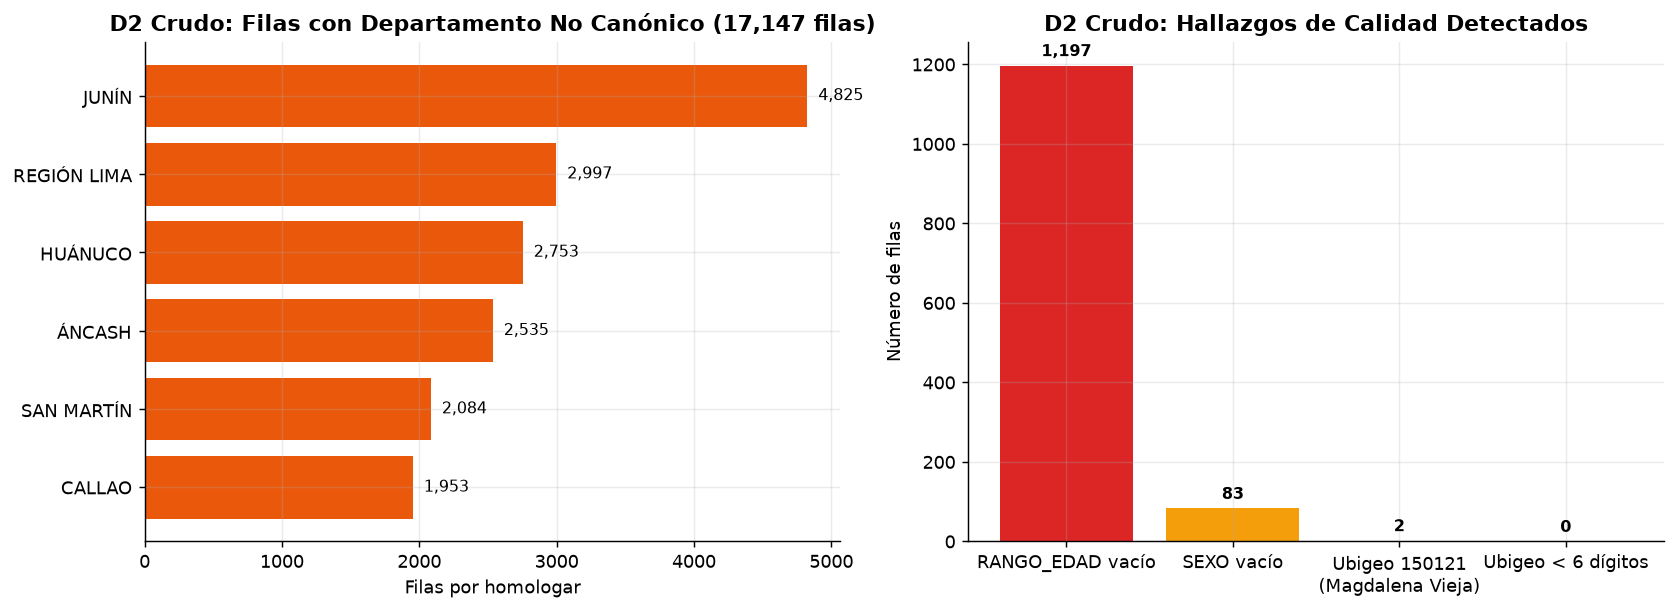

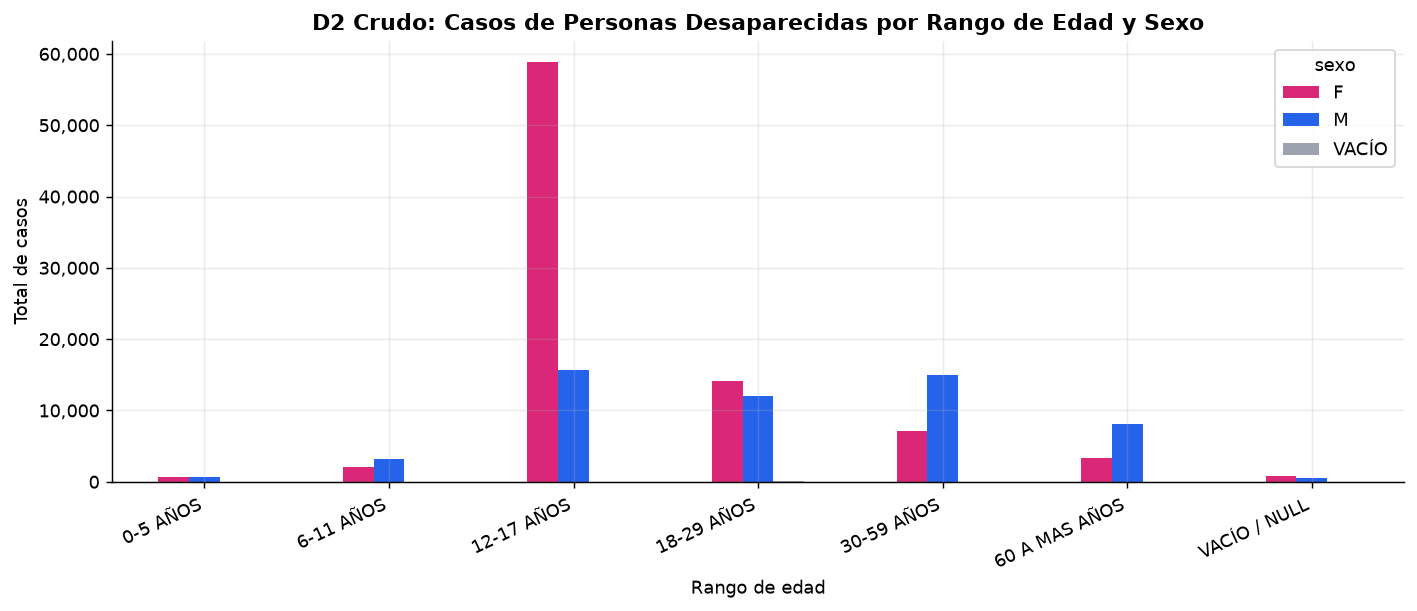

In [7]:
# Gráfica 3: Problemas de calidad en D2 (departamentos por homologar y vacíos)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

df_nc = d2_dptos_no_canon.sort_values("filas", ascending=True)
bars = axes[0].barh(df_nc["dpto_crudo"], df_nc["filas"], color="#EA580C")
axes[0].set_title("D2 Crudo: Filas con Departamento No Canónico (17,147 filas)", fontweight="bold")
axes[0].set_xlabel("Filas por homologar")
for b in bars:
    w = b.get_width()
    axes[0].text(w + 80, b.get_y() + b.get_height()/2, f"{int(w):,}", va="center", fontsize=9)

# Subgráfico 2: Campos vacíos y ubigeo sin cero inicial
anomalias_d2 = pd.DataFrame({
    "Anomalía": ["RANGO_EDAD vacío", "SEXO vacío", "Ubigeo 150121\n(Magdalena Vieja)", "Ubigeo < 6 dígitos"],
    "Filas": [
        int(d2_calidad.loc[0, "filas_rango_edad_vacio"]),
        int(d2_calidad.loc[0, "filas_sexo_vacio"]),
        int(d2_conflicto_150121[d2_conflicto_150121["distrito"] == "MAGDALENA VIEJA"]["filas"].sum()),
        int(d2_calidad.loc[0, "ubigeos_sin_cero_izq"]),
    ]
})
bars2 = axes[1].bar(anomalias_d2["Anomalía"], anomalias_d2["Filas"], color=["#DC2626", "#F59E0B", "#7C3AED", "#0284C7"])
axes[1].set_title("D2 Crudo: Hallazgos de Calidad Detectados", fontweight="bold")
axes[1].set_ylabel("Número de filas")
for b in bars2:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, h + max(anomalias_d2["Filas"])*0.02, f"{int(h):,}", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(OUT_DIR / "03_crudo_desaparecidos_calidad.png", dpi=150, bbox_inches="tight")
plt.show()

# Gráfica 4: Perfil crudo por rango de edad y sexo
orden_edad = ["0-5 AÑOS", "6-11 AÑOS", "12-17 AÑOS", "18-29 AÑOS", "30-59 AÑOS", "60 A MAS AÑOS", "VACÍO / NULL"]
piv = d2_perfil.pivot_table(index="rango_edad", columns="sexo", values="casos", aggfunc="sum", fill_value=0)
piv = piv.reindex([e for e in orden_edad if e in piv.index])

fig, ax = plt.subplots(figsize=(11, 4.8))
piv.plot(kind="bar", ax=ax, color={"F": "#DB2777", "M": "#2563EB", "VACÍO": "#9CA3AF"})
ax.set_title("D2 Crudo: Casos de Personas Desaparecidas por Rango de Edad y Sexo", fontweight="bold")
ax.set_xlabel("Rango de edad")
ax.set_ylabel("Total de casos")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(OUT_DIR / "04_crudo_desaparecidos_perfil.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. EDA Crudo — Dataset 3: Producción Policial (2023–2026)

Consultas **PySpark SQL** para diagnosticar:
- Meses codificados como abreviaturas en español (`ENE`, `FEB`, ..., `SET`, ..., `DIC`), incompatibles con los meses numéricos `1–12` de D1 y D2.
- Cobertura parcial de **2026** (10 meses: `ENE`–`OCT`).
- Proporción de **valores cero** (`VALOR = 0` indica sin operativos/resultados reportados; no son nulos).
- Inconsistencias en `DIR_REG_FRE` (`Región` con tilde/minúscula; `RP ICA` y `RP TUMBES` repetidos como tipo).
- Mezcla de **18 variables** con distintas magnitudes en una sola columna `VALOR` (sin columna `unidad_medida` en el origen).

In [8]:
d3_anual = spark.sql("""
    SELECT CAST(`AÑO` AS INT) AS anio,
           COUNT(*) AS filas,
           COUNT(DISTINCT TRIM(MES)) AS meses_distintos,
           SUM(CASE WHEN CAST(VALOR AS DOUBLE) = 0 THEN 1 ELSE 0 END) AS filas_cero,
           SUM(CASE WHEN CAST(VALOR AS DOUBLE) > 0 THEN 1 ELSE 0 END) AS filas_positivas,
           ROUND(100.0 * SUM(CASE WHEN CAST(VALOR AS DOUBLE) = 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_ceros
    FROM raw_produccion
    GROUP BY CAST(`AÑO` AS INT)
    ORDER BY anio
""").toPandas()

d3_meses = spark.sql("""
    SELECT TRIM(MES) AS mes_texto, COUNT(*) AS filas
    FROM raw_produccion
    GROUP BY TRIM(MES)
    ORDER BY filas DESC
""").toPandas()

d3_dir_reg = spark.sql("""
    SELECT TRIM(DIR_REG_FRE) AS dir_reg_fre_crudo,
           COUNT(DISTINCT TRIM(DEPENDENCIAS)) AS dependencias,
           COUNT(*) AS filas
    FROM raw_produccion
    GROUP BY TRIM(DIR_REG_FRE)
    ORDER BY filas DESC
""").toPandas()

d3_variables = spark.sql("""
    SELECT TRIM(VARIABLE) AS variable,
           COUNT(*) AS filas,
           ROUND(SUM(CAST(VALOR AS DOUBLE)), 2) AS suma_bruta,
           SUM(CASE WHEN CAST(VALOR AS DOUBLE) = 0 THEN 1 ELSE 0 END) AS filas_cero
    FROM raw_produccion
    GROUP BY TRIM(VARIABLE)
    ORDER BY variable
""").toPandas()

d3_calidad = spark.sql("""
    SELECT
        COUNT(*) AS total_filas,
        SUM(CASE WHEN CAST(VALOR AS DOUBLE) = 0 THEN 1 ELSE 0 END) AS filas_valor_cero,
        SUM(CASE WHEN CAST(VALOR AS DOUBLE) < 0 THEN 1 ELSE 0 END) AS valores_negativos,
        SUM(CASE WHEN TRIM(DIR_REG_FRE) = 'Región' THEN 1 ELSE 0 END) AS filas_region_tilde,
        SUM(CASE WHEN TRIM(DIR_REG_FRE) IN ('RP ICA', 'RP TUMBES') THEN 1 ELSE 0 END) AS filas_dir_inconsistente,
        COUNT(DISTINCT TRIM(VARIABLE)) AS variables_mezcladas,
        COUNT(*) - COUNT(DISTINCT CONCAT_WS('|', `AÑO`, TRIM(MES), TRIM(DEPENDENCIAS), TRIM(VARIABLE))) AS duplicados_grano
    FROM raw_produccion
""").toPandas()

d3_anual.to_csv(OUT_DIR / "d3_crudo_anual.csv", index=False, encoding="utf-8-sig")
d3_dir_reg.to_csv(OUT_DIR / "d3_crudo_dir_reg_fre.csv", index=False, encoding="utf-8-sig")
d3_variables.to_csv(OUT_DIR / "d3_crudo_variables.csv", index=False, encoding="utf-8-sig")

display(d3_calidad)
display(d3_anual)
display(d3_dir_reg)

,total_filas,filas_valor_cero,valores_negativos,filas_region_tilde,filas_dir_inconsistente,variables_mezcladas,duplicados_grano
0,39096,15458,0,19836,792,18,0


,anio,filas,meses_distintos,filas_cero,filas_positivas,pct_ceros
0,2023,9936,12,4337,5599,43.65
1,2024,9936,12,3738,6198,37.62
2,2025,10584,12,4062,6522,38.38
3,2026,8640,10,3321,5319,38.44


,dir_reg_fre_crudo,dependencias,filas
0,Región,25,19836
1,DIRNIC,12,9504
2,DIRNOS,8,5760
3,Frente,6,3204
4,RP TUMBES,1,396
5,RP ICA,1,396


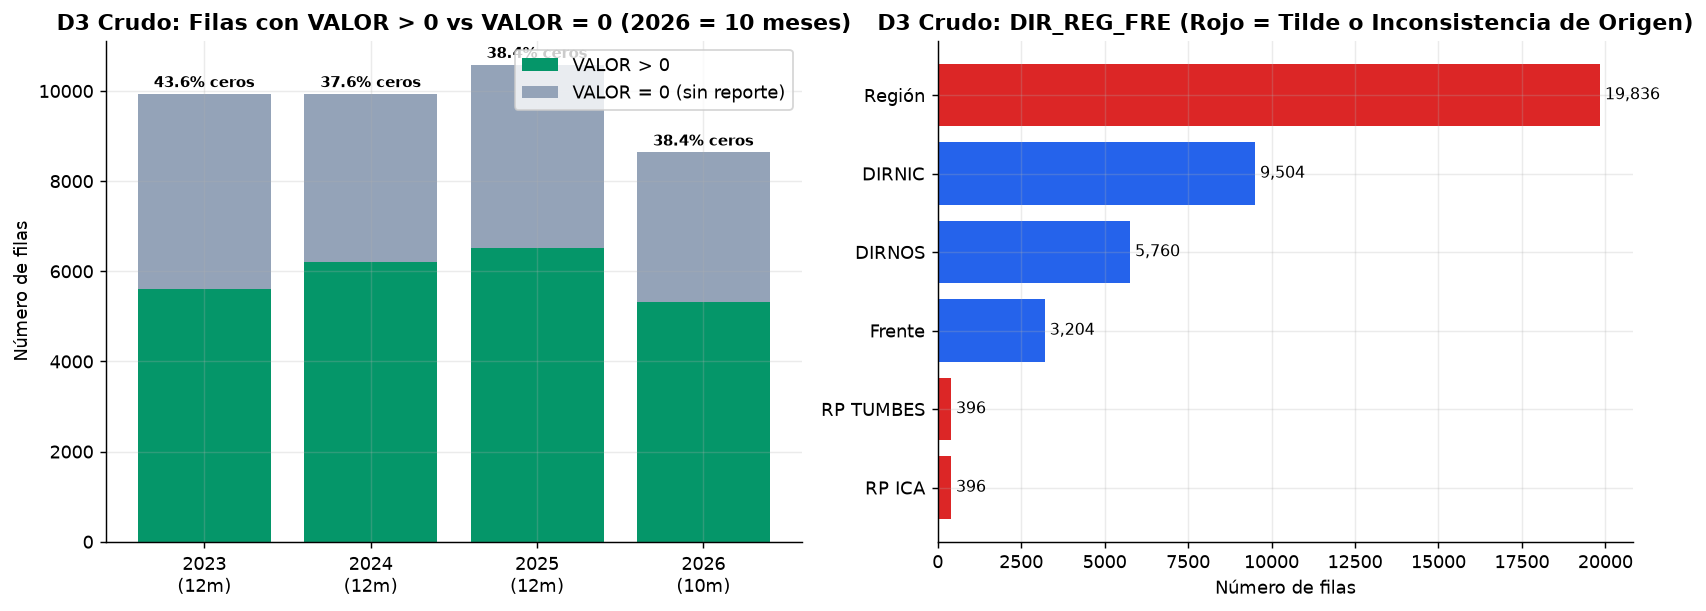

In [9]:
# Gráfica 5: Ceros vs Positivos por año y meses (D3)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

x = range(len(d3_anual))
axes[0].bar(x, d3_anual["filas_positivas"], label="VALOR > 0", color="#059669")
axes[0].bar(x, d3_anual["filas_cero"], bottom=d3_anual["filas_positivas"], label="VALOR = 0 (sin reporte)", color="#94A3B8")
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{a}\n({m}m)" for a, m in zip(d3_anual["anio"], d3_anual["meses_distintos"])])
axes[0].set_title("D3 Crudo: Filas con VALOR > 0 vs VALOR = 0 (2026 = 10 meses)", fontweight="bold")
axes[0].set_ylabel("Número de filas")
axes[0].legend()
for i, row in d3_anual.iterrows():
    axes[0].text(i, row["filas"] + 150, f"{row['pct_ceros']:.1f}% ceros", ha="center", fontsize=8.5, fontweight="bold")

# Subgráfico 2: DIR_REG_FRE crudo con inconsistencias
df_dr = d3_dir_reg.sort_values("filas", ascending=True)
colors_dr = ["#DC2626" if v in ("Región", "RP ICA", "RP TUMBES") else "#2563EB" for v in df_dr["dir_reg_fre_crudo"]]
bars2 = axes[1].barh(df_dr["dir_reg_fre_crudo"], df_dr["filas"], color=colors_dr)
axes[1].set_title("D3 Crudo: DIR_REG_FRE (Rojo = Tilde o Inconsistencia de Origen)", fontweight="bold")
axes[1].set_xlabel("Número de filas")
for b in bars2:
    w = b.get_width()
    axes[1].text(w + 150, b.get_y() + b.get_height()/2, f"{int(w):,}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(OUT_DIR / "05_crudo_produccion_calidad.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. EDA Crudo — Dataset 4: Victimización y Confianza PNP (2013–2024)

Consultas **PySpark SQL** para diagnosticar:
- Columna constante `PERIODO = 'AÑO'` en el 100% de las filas (sin columna de mes → grano anual).
- Cobertura incompleta de **2013** (`107` filas vs `135` esperadas: falta `PORCENTAJE DE CONFIANZA EN LA PNP` y la fila nacional de victimización).
- Mezcla de `AMBITO_PROY = 'NACIONAL'` dentro de `DEPARTAMENTO` (`58` filas).
- **6 filas con `COD_UBICACION` desalineado en 2013** detectadas automáticamente con PySpark SQL al comparar contra el código mayoritario de cada departamento en 2014–2024.
- **354 filas** con departamentos con tilde por homologar al formato canónico sin tildes.

In [10]:
d4_anual = spark.sql("""
    SELECT CAST(`VALOR PERIODO` AS INT) AS anio,
           COUNT(*) AS filas,
           COUNT(DISTINCT TRIM(INDICADOR)) AS indicadores,
           SUM(CASE WHEN TRIM(AMBITO_PROY) = 'NACIONAL' THEN 1 ELSE 0 END) AS filas_nacionales
    FROM raw_victimizacion
    GROUP BY CAST(`VALOR PERIODO` AS INT)
    ORDER BY anio
""").toPandas()

d4_periodo = spark.sql("""
    SELECT TRIM(PERIODO) AS periodo_valor, COUNT(*) AS filas
    FROM raw_victimizacion
    GROUP BY TRIM(PERIODO)
""").toPandas()

# Detección automática en PySpark SQL de los 6 códigos desalineados en 2013
d4_codigos_desalineados = spark.sql("""
    WITH ref AS (
        SELECT UPPER(TRIM(DEPARTAMENTO)) AS dpto,
               CAST(COD_UBICACION AS INT) AS cod_esperado,
               COUNT(*) AS freq,
               ROW_NUMBER() OVER (PARTITION BY UPPER(TRIM(DEPARTAMENTO)) ORDER BY COUNT(*) DESC) AS rn
        FROM raw_victimizacion
        WHERE CAST(`VALOR PERIODO` AS INT) >= 2014
        GROUP BY UPPER(TRIM(DEPARTAMENTO)), CAST(COD_UBICACION AS INT)
    )
    SELECT CAST(v.`VALOR PERIODO` AS INT) AS anio,
           TRIM(v.INDICADOR) AS indicador,
           TRIM(v.DEPARTAMENTO) AS departamento,
           CAST(v.COD_UBICACION AS INT) AS cod_crudo,
           r.cod_esperado,
           CAST(v.VALOR AS DOUBLE) AS valor
    FROM raw_victimizacion v
    JOIN ref r ON UPPER(TRIM(v.DEPARTAMENTO)) = r.dpto AND r.rn = 1
    WHERE CAST(v.COD_UBICACION AS INT) <> r.cod_esperado
    ORDER BY departamento
""").toPandas()

d4_indicadores = spark.sql("""
    SELECT TRIM(INDICADOR) AS indicador,
           COUNT(*) AS filas,
           ROUND(MIN(CAST(VALOR AS DOUBLE)), 1) AS min_pct,
           ROUND(AVG(CAST(VALOR AS DOUBLE)), 1) AS promedio_pct,
           ROUND(MAX(CAST(VALOR AS DOUBLE)), 1) AS max_pct
    FROM raw_victimizacion
    GROUP BY TRIM(INDICADOR)
    ORDER BY promedio_pct DESC
""").toPandas()

d4_calidad = spark.sql("""
    SELECT
        COUNT(*) AS total_filas,
        SUM(CASE WHEN TRIM(AMBITO_PROY) = 'NACIONAL' THEN 1 ELSE 0 END) AS filas_nacionales_en_dpto,
        SUM(CASE WHEN UPPER(TRIM(DEPARTAMENTO)) IN ('ÁNCASH','APURÍMAC','HUÁNUCO','JUNÍN','SAN MARTÍN','REGIÓN LIMA') THEN 1 ELSE 0 END) AS filas_dpto_con_tilde,
        SUM(CASE WHEN CAST(VALOR AS DOUBLE) < 0 OR CAST(VALOR AS DOUBLE) > 100 THEN 1 ELSE 0 END) AS valores_fuera_rango,
        COUNT(DISTINCT TRIM(PERIODO)) AS valores_distintos_periodo
    FROM raw_victimizacion
""").toPandas()

d4_anual.to_csv(OUT_DIR / "d4_crudo_anual.csv", index=False, encoding="utf-8-sig")
d4_codigos_desalineados.to_csv(OUT_DIR / "d4_crudo_codigos_desalineados.csv", index=False, encoding="utf-8-sig")
d4_indicadores.to_csv(OUT_DIR / "d4_crudo_indicadores.csv", index=False, encoding="utf-8-sig")

display(d4_calidad)
print("--- 6 filas con COD_UBICACION desalineado en 2013 ---")
display(d4_codigos_desalineados)
display(d4_indicadores)

,total_filas,filas_nacionales_en_dpto,filas_dpto_con_tilde,valores_fuera_rango,valores_distintos_periodo
0,1592,58,354,0,1


--- 6 filas con COD_UBICACION desalineado en 2013 ---


,anio,indicador,departamento,cod_crudo,cod_esperado,valor
0,2013,PORCENTAJE DE VICTIMIZACIÓN POR ESTAFA,LORETO,15,16,6.9
1,2013,PORCENTAJE DE VICTIMIZACIÓN POR ESTAFA,MADRE DE DIOS,16,17,6.8
2,2013,PORCENTAJE DE VICTIMIZACIÓN POR ESTAFA,MOQUEGUA,17,18,4.8
3,2013,PORCENTAJE DE VICTIMIZACIÓN POR ESTAFA,PASCO,18,19,14.4
4,2013,PORCENTAJE DE VICTIMIZACIÓN POR ESTAFA,PIURA,19,20,11.4
5,2013,PORCENTAJE DE VICTIMIZACIÓN POR ESTAFA,PROV. CONST. DEL CALLAO,20,7,11.0


,indicador,filas,min_pct,promedio_pct,max_pct
0,PORCENTAJE DE PERCEPCIÓN DE INSEGURIDAD AL CAM...,324,12.5,50.4,76.7
1,PORCENTAJE DE VICTIMIZACIÓN,323,8.4,24.3,46.3
2,PORCENTAJE DE CONFIANZA EN LA PNP,297,4.4,19.4,39.7
3,PORCENTAJE DE VICTIMIZACIÓN POR EL DELITO DE R...,324,2.5,14.6,29.6
4,PORCENTAJE DE VICTIMIZACIÓN POR ESTAFA,324,0.2,5.1,17.9


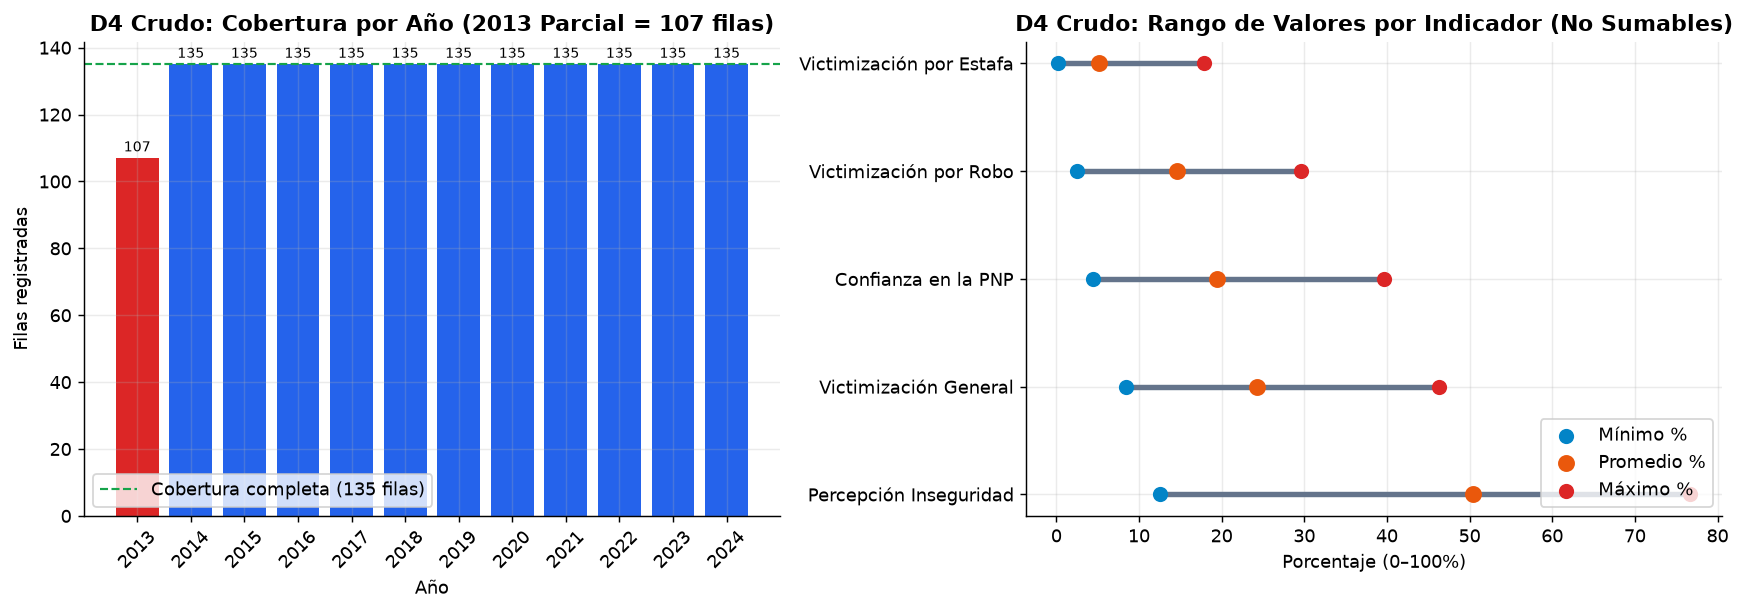

In [11]:
# Gráfica 6: Cobertura anual D4 (2013 parcial) y rangos de los 5 indicadores
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

colors_v = ["#DC2626" if f < 135 else "#2563EB" for f in d4_anual["filas"]]
bars = axes[0].bar(d4_anual["anio"].astype(str), d4_anual["filas"], color=colors_v)
axes[0].axhline(135, color="#16A34A", linestyle="--", linewidth=1.2, label="Cobertura completa (135 filas)")
axes[0].set_title("D4 Crudo: Cobertura por Año (2013 Parcial = 107 filas)", fontweight="bold")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Filas registradas")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()
for b in bars:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 2, f"{int(h)}", ha="center", fontsize=8)

# Subgráfico 2: Rangos (min - promedio - max) por indicador
short_names = {
    "PORCENTAJE DE PERCEPCIÓN DE INSEGURIDAD AL CAMINAR SOLO(A) DE NOCHE EN SU ZONA O BARRIO": "Percepción Inseguridad",
    "PORCENTAJE DE VICTIMIZACIÓN": "Victimización General",
    "PORCENTAJE DE CONFIANZA EN LA PNP": "Confianza en la PNP",
    "PORCENTAJE DE VICTIMIZACIÓN POR EL DELITO DE ROBO E INTENTO DE ROBO DE DINERO, CARTERA Y CELULAR": "Victimización por Robo",
    "PORCENTAJE DE VICTIMIZACIÓN POR ESTAFA": "Victimización por Estafa",
}
d4_ind_plot = d4_indicadores.copy()
d4_ind_plot["nombre_corto"] = d4_ind_plot["indicador"].map(lambda s: short_names.get(s, s[:28]))
y_pos = range(len(d4_ind_plot))
axes[1].hlines(y=y_pos, xmin=d4_ind_plot["min_pct"], xmax=d4_ind_plot["max_pct"], color="#64748B", linewidth=3)
axes[1].scatter(d4_ind_plot["min_pct"], y_pos, color="#0284C7", s=55, label="Mínimo %", zorder=3)
axes[1].scatter(d4_ind_plot["promedio_pct"], y_pos, color="#EA580C", s=70, label="Promedio %", zorder=4)
axes[1].scatter(d4_ind_plot["max_pct"], y_pos, color="#DC2626", s=55, label="Máximo %", zorder=3)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(d4_ind_plot["nombre_corto"])
axes[1].set_xlabel("Porcentaje (0–100%)")
axes[1].set_title("D4 Crudo: Rango de Valores por Indicador (No Sumables)", fontweight="bold")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig(OUT_DIR / "06_crudo_victimizacion_cobertura_rangos.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Consolidación de Hallazgos de Calidad y Exportación para Streamlit

Consolidamos todos los problemas detectados en los 4 datasets crudos junto con la regla ETL que los resuelve, y exportamos `resumen_crudos.json` y `matriz_hallazgos_crudos.csv` en `EDA/EDA-Datos-Crudos/outputs/`.

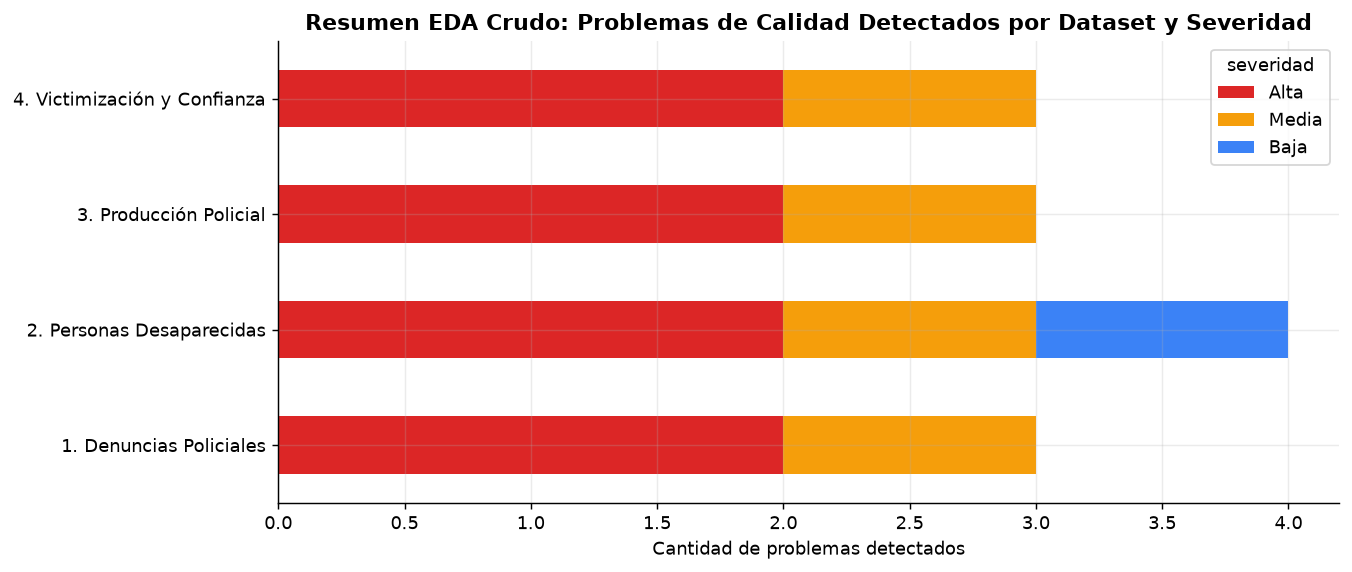

Exportación completada en: C:\Users\rodry20x\Documents\Clases-UPN\Ciclo_2026-2\BigDATA\EF_Final\EDA\EDA-Datos-Crudos\outputs


,dataset,problema,severidad,filas_afectadas,accion_etl
0,1. Denuncias Policiales,Ubigeos con cero inicial perdido (< 6 dígitos),Alta,146690,Normalizar UBIGEO_HECHO con LPAD a 6 dígitos (...
1,1. Denuncias Policiales,Conflicto de provincia en ubigeo 160801 (MAYNA...,Media,107,Homologar 160801 a LORETO / PUTUMAYO / PUTUMAYO.
2,1. Denuncias Policiales,"Año 2026 incompleto (solo enero–octubre, 10 me...",Alta,37683,Etiquetar es_anio_parcial = 1 para excluir de ...
3,2. Personas Desaparecidas,Codificación CP1252 (corrompe tildes y Ñ si se...,Alta,77331,Convertir copia fiel a UTF-8 con BOM y cargar ...
4,2. Personas Desaparecidas,Departamentos con tildes o CALLAO distinto al ...,Alta,17147,Homologar 6 nombres al estilo canónico sin til...
5,2. Personas Desaparecidas,"Valores vacíos en SEXO (83) y RANGO_EDAD (1,197)",Media,1280,Preservar como NULL en DataMart y mapear a NO ...
6,2. Personas Desaparecidas,Conflicto de distrito en ubigeo 150121 (PUEBLO...,Baja,70,Homologar 150121 a LIMA METROPOLITANA / LIMA /...
7,3. Producción Policial,Meses como texto abreviado (ENE..SET..DIC) y 2...,Alta,39096,Convertir abreviaturas a mes_registro (1–12) y...
8,3. Producción Policial,18 variables con magnitudes incompatibles mezc...,Alta,39096,"Derivar columna unidad_medida (KILOS, SOLES, P..."
9,3. Producción Policial,DIR_REG_FRE con 'Región' (tilde) y valores 'RP...,Media,20628,Homologar Región -> REGION y documentar incons...


In [12]:
hallazgos = [
    {
        "dataset": "1. Denuncias Policiales",
        "problema": "Ubigeos con cero inicial perdido (< 6 dígitos)",
        "severidad": "Alta",
        "filas_afectadas": int(d1_calidad.loc[0, "ubigeos_5_digitos"]),
        "accion_etl": "Normalizar UBIGEO_HECHO con LPAD a 6 dígitos (CHAR(6)).",
    },
    {
        "dataset": "1. Denuncias Policiales",
        "problema": "Conflicto de provincia en ubigeo 160801 (MAYNAS vs PUTUMAYO)",
        "severidad": "Media",
        "filas_afectadas": int(d1_conflicto_160801["filas"].sum()),
        "accion_etl": "Homologar 160801 a LORETO / PUTUMAYO / PUTUMAYO.",
    },
    {
        "dataset": "1. Denuncias Policiales",
        "problema": "Año 2026 incompleto (solo enero–octubre, 10 meses)",
        "severidad": "Alta",
        "filas_afectadas": int(d1_anual.loc[d1_anual["anio"] == 2026, "filas"].iloc[0]),
        "accion_etl": "Etiquetar es_anio_parcial = 1 para excluir de comparativas anuales.",
    },
    {
        "dataset": "2. Personas Desaparecidas",
        "problema": "Codificación CP1252 (corrompe tildes y Ñ si se lee como UTF-8)",
        "severidad": "Alta",
        "filas_afectadas": int(d2_calidad.loc[0, "total_filas"]),
        "accion_etl": "Convertir copia fiel a UTF-8 con BOM y cargar con N'...' y sqlcmd -f 65001.",
    },
    {
        "dataset": "2. Personas Desaparecidas",
        "problema": "Departamentos con tildes o CALLAO distinto al canónico",
        "severidad": "Alta",
        "filas_afectadas": int(d2_calidad.loc[0, "filas_dpto_no_canonico"]),
        "accion_etl": "Homologar 6 nombres al estilo canónico sin tildes y PROV. CONST. DEL CALLAO.",
    },
    {
        "dataset": "2. Personas Desaparecidas",
        "problema": "Valores vacíos en SEXO (83) y RANGO_EDAD (1,197)",
        "severidad": "Media",
        "filas_afectadas": int(d2_calidad.loc[0, "filas_sexo_vacio"] + d2_calidad.loc[0, "filas_rango_edad_vacio"]),
        "accion_etl": "Preservar como NULL en DataMart y mapear a NO INFORMADO en DW.",
    },
    {
        "dataset": "2. Personas Desaparecidas",
        "problema": "Conflicto de distrito en ubigeo 150121 (PUEBLO LIBRE vs MAGDALENA VIEJA)",
        "severidad": "Baja",
        "filas_afectadas": int(d2_conflicto_150121["filas"].sum()),
        "accion_etl": "Homologar 150121 a LIMA METROPOLITANA / LIMA / PUEBLO LIBRE.",
    },
    {
        "dataset": "3. Producción Policial",
        "problema": "Meses como texto abreviado (ENE..SET..DIC) y 2026 parcial (10 meses)",
        "severidad": "Alta",
        "filas_afectadas": int(d3_calidad.loc[0, "total_filas"]),
        "accion_etl": "Convertir abreviaturas a mes_registro (1–12) y marcar 2026 es_anio_parcial = 1.",
    },
    {
        "dataset": "3. Producción Policial",
        "problema": "18 variables con magnitudes incompatibles mezcladas en VALOR",
        "severidad": "Alta",
        "filas_afectadas": int(d3_calidad.loc[0, "total_filas"]),
        "accion_etl": "Derivar columna unidad_medida (KILOS, SOLES, PERSONAS, etc.).",
    },
    {
        "dataset": "3. Producción Policial",
        "problema": "DIR_REG_FRE con 'Región' (tilde) y valores 'RP ICA'/'RP TUMBES'",
        "severidad": "Media",
        "filas_afectadas": int(d3_calidad.loc[0, "filas_region_tilde"] + d3_calidad.loc[0, "filas_dir_inconsistente"]),
        "accion_etl": "Homologar Región -> REGION y documentar inconsistencia RP ICA / RP TUMBES.",
    },
    {
        "dataset": "4. Victimización y Confianza",
        "problema": "Codificación CP1252, columna PERIODO constante y grano anual sin mes",
        "severidad": "Media",
        "filas_afectadas": int(d4_calidad.loc[0, "total_filas"]),
        "accion_etl": "Convertir a UTF-8, eliminar PERIODO, renombrar VALOR PERIODO -> anio_registro.",
    },
    {
        "dataset": "4. Victimización y Confianza",
        "problema": "6 filas de 2013 con COD_UBICACION desalineado respecto al departamento",
        "severidad": "Alta",
        "filas_afectadas": int(len(d4_codigos_desalineados)),
        "accion_etl": "Re-derivar cod_ubicacion canónico desde DEPARTAMENTO.",
    },
    {
        "dataset": "4. Victimización y Confianza",
        "problema": "Año 2013 parcial (107 vs 135 filas) y mezcla NACIONAL en DEPARTAMENTO (58 filas)",
        "severidad": "Alta",
        "filas_afectadas": int(d4_anual.loc[d4_anual["anio"] == 2013, "filas"].iloc[0] + d4_calidad.loc[0, "filas_nacionales_en_dpto"]),
        "accion_etl": "Marcar 2013 es_anio_parcial = 1 y separar ambito='NACIONAL' con departamento = NULL.",
    },
]

df_hallazgos = pd.DataFrame(hallazgos)
df_hallazgos.to_csv(OUT_DIR / "matriz_hallazgos_crudos.csv", index=False, encoding="utf-8-sig")

# Gráfica 7: Resumen de hallazgos por dataset y severidad
fig, ax = plt.subplots(figsize=(10.5, 4.5))
sev_counts = df_hallazgos.groupby(["dataset", "severidad"]).size().unstack(fill_value=0)
for col in ["Alta", "Media", "Baja"]:
    if col not in sev_counts.columns:
        sev_counts[col] = 0
sev_counts = sev_counts[["Alta", "Media", "Baja"]]
sev_counts.plot(kind="barh", stacked=True, ax=ax, color={"Alta": "#DC2626", "Media": "#F59E0B", "Baja": "#3B82F6"})
ax.set_title("Resumen EDA Crudo: Problemas de Calidad Detectados por Dataset y Severidad", fontweight="bold")
ax.set_xlabel("Cantidad de problemas detectados")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(OUT_DIR / "07_crudo_resumen_hallazgos.png", dpi=150, bbox_inches="tight")
plt.show()

# Guardar JSON consolidado para Streamlit y comparativa Antes vs Después
resumen_json = {
    "etapa": "Datos Crudos (Pre-ETL)",
    "motor": f"PySpark SQL {spark.version}",
    "total_archivos_csv": int(len(df_archivos)),
    "archivos_cp1252": int((~df_archivos["utf8_valido"]).sum()),
    "total_filas_crudas": int(resumen_general_df["filas_crudas"].sum()),
    "total_hallazgos": int(len(hallazgos)),
    "datasets": {
        "denuncias": {
            "filas": int(d1_calidad.loc[0, "total_filas"]),
            "total_denuncias": int(d1_calidad.loc[0, "total_denuncias"]),
            "ubigeos_5_digitos": int(d1_calidad.loc[0, "ubigeos_5_digitos"]),
            "conflicto_160801_filas": int(d1_conflicto_160801["filas"].sum()),
            "duplicados_grano": int(d1_calidad.loc[0, "duplicados_grano"]),
            "anio_parcial": 2026,
            "meses_2026": int(d1_anual.loc[d1_anual["anio"] == 2026, "meses_distintos"].iloc[0]),
            "codificacion": "UTF-8",
        },
        "desaparecidos": {
            "filas": int(d2_calidad.loc[0, "total_filas"]),
            "total_casos": int(d2_calidad.loc[0, "total_casos"]),
            "sexo_vacio": int(d2_calidad.loc[0, "filas_sexo_vacio"]),
            "rango_edad_vacio": int(d2_calidad.loc[0, "filas_rango_edad_vacio"]),
            "dptos_no_canonicos": int(d2_calidad.loc[0, "filas_dpto_no_canonico"]),
            "conflicto_150121_filas": int(d2_conflicto_150121["filas"].sum()),
            "ubigeos_sin_cero_izq": int(d2_calidad.loc[0, "ubigeos_sin_cero_izq"]),
            "duplicados_grano": int(d2_calidad.loc[0, "duplicados_grano"]),
            "codificacion": "CP1252",
        },
        "produccion": {
            "filas": int(d3_calidad.loc[0, "total_filas"]),
            "filas_valor_cero": int(d3_calidad.loc[0, "filas_valor_cero"]),
            "filas_region_tilde": int(d3_calidad.loc[0, "filas_region_tilde"]),
            "filas_dir_inconsistente": int(d3_calidad.loc[0, "filas_dir_inconsistente"]),
            "variables_mezcladas": int(d3_calidad.loc[0, "variables_mezcladas"]),
            "mes_en_texto": True,
            "anio_parcial": 2026,
            "meses_2026": int(d3_anual.loc[d3_anual["anio"] == 2026, "meses_distintos"].iloc[0]),
            "duplicados_grano": int(d3_calidad.loc[0, "duplicados_grano"]),
            "codificacion": "UTF-8 BOM",
        },
        "victimizacion": {
            "filas": int(d4_calidad.loc[0, "total_filas"]),
            "codigos_desalineados_2013": int(len(d4_codigos_desalineados)),
            "dptos_con_tilde": int(d4_calidad.loc[0, "filas_dpto_con_tilde"]),
            "filas_nacionales_en_dpto": int(d4_calidad.loc[0, "filas_nacionales_en_dpto"]),
            "periodo_constante": True,
            "anio_parcial": 2013,
            "filas_2013": int(d4_anual.loc[d4_anual["anio"] == 2013, "filas"].iloc[0]),
            "codificacion": "CP1252",
        },
    },
    "hallazgos": hallazgos,
}

(OUT_DIR / "resumen_crudos.json").write_text(
    json.dumps(resumen_json, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Exportación completada en:", OUT_DIR)
display(df_hallazgos)
spark.stop()